In [1]:

import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout 
from keras.preprocessing.image import ImageDataGenerator
from keras.optimizers import Adam

from sklearn.metrics import classification_report,confusion_matrix
import tensorflow as tf

import cv2
import os

import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings("ignore")


In [2]:
#data_dir='modeldata/main_gmap'
data_dir='modeldata'
labels = ['building', 'other']
img_size = 224  #224
def get_data(data_dir):
    data = [] 
    for label in labels: 
        path = os.path.join(data_dir, label)
        class_num = labels.index(label)
        
        cnt=0
        for img in os.listdir(path):
            #if cnt<=1000:
            try:
                img_arr = cv2.imread(os.path.join(path, img))[...,::-1] #convert BGR to RGB format
                
                img_gray = cv2.cvtColor(img_arr, cv2.COLOR_BGR2GRAY)
                #ret, thresh = cv2.threshold(img_gray, 125, 255, cv2.THRESH_BINARY)
                ret, thresh = cv2.threshold(img_gray, 0, 1, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
                
                resized_arr = cv2.resize(thresh, (img_size, img_size)) # Reshaping images to preferred size
                data.append([resized_arr, class_num])
                cnt=cnt+1
            except Exception as e:
                print(e)
    return np.array(data)

<Axes: xlabel='data', ylabel='count'>

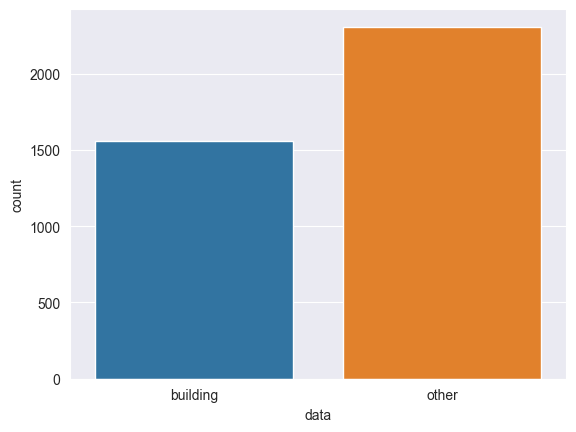

In [3]:
alldata=get_data(data_dir)

l = []
for i in alldata:
    if(i[1] == 0):
        l.append("building")
    else:
        l.append("other")
sns.set_style('darkgrid')
sns.countplot(pd.DataFrame(data=l,columns=['data']),x='data')

In [4]:
from sklearn.model_selection import train_test_split

train, val = train_test_split(alldata, test_size=0.2, random_state=7)


labels = ['building', 'other']
train  = get_data('C:/DEV/imageprocess/modeldata/main_gmap/train')
val    = get_data('C:/DEV/imageprocess/modeldata/main_gmap/test')

<Axes: xlabel='data', ylabel='count'>

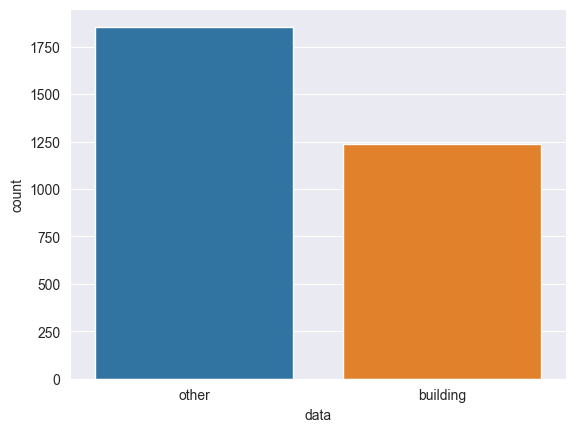

In [5]:
l = []
for i in train:
    if(i[1] == 0):
        l.append("building")
    else:
        l.append("other")
sns.set_style('darkgrid')
sns.countplot(pd.DataFrame(data=l,columns=['data']),x='data')

<Axes: xlabel='data', ylabel='count'>

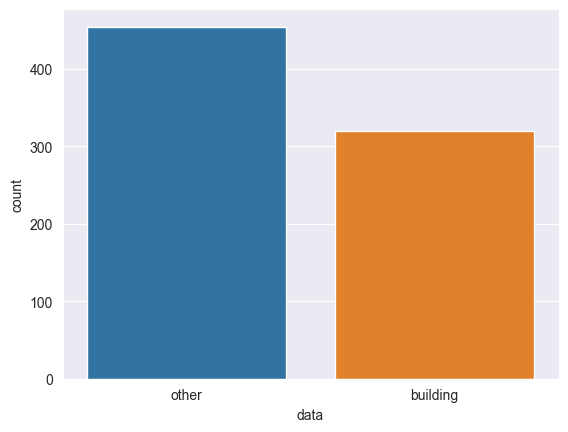

In [6]:
l = []
for i in val:
    if(i[1] == 0):
        l.append("building")
    else:
        l.append("other")
sns.set_style('darkgrid')
sns.countplot(pd.DataFrame(data=l,columns=['data']),x='data')

Text(0.5, 1.0, 'building')

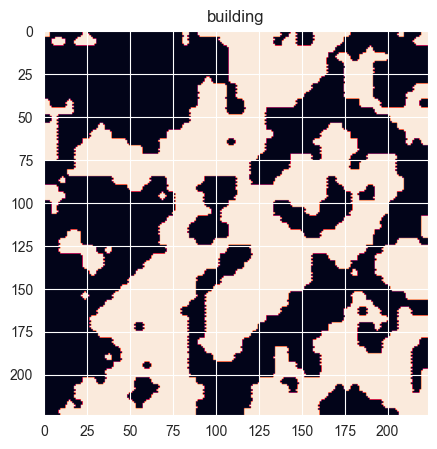

In [7]:
plt.figure(figsize = (5,5))
plt.imshow(train[5][0])
plt.title(labels[train[5][1]])

Text(0.5, 1.0, 'other')

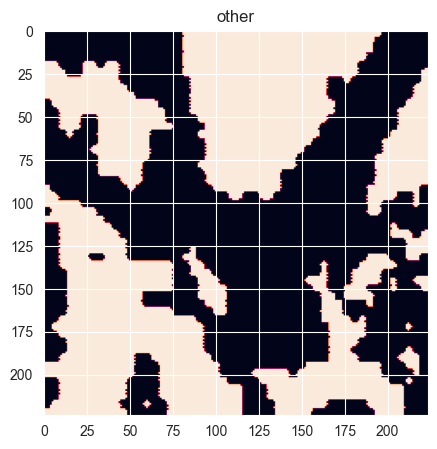

In [8]:
plt.figure(figsize = (5,5))
plt.imshow(train[0][0])
plt.title(labels[train[0][1]])

In [9]:
x_train = []
y_train = []
x_val = []
y_val = []

for feature, label in train:
    x_train.append(feature)
    y_train.append(label)

for feature, label in val:
    x_val.append(feature)
    y_val.append(label)

# Normalize the data
x_train = np.array(x_train) / 255
x_val = np.array(x_val) / 255

x_train.reshape(-1, img_size, img_size, 1)
y_train = np.array(y_train)

x_val.reshape(-1, img_size, img_size, 1)
y_val = np.array(y_val)

In [10]:
datagen = ImageDataGenerator(
        featurewise_center=False,  # set input mean to 0 over the dataset
        samplewise_center=False,  # set each sample mean to 0
        featurewise_std_normalization=False,  # divide inputs by std of the dataset
        samplewise_std_normalization=False,  # divide each input by its std
        zca_whitening=False,  # apply ZCA whitening
        rotation_range = 180,  # randomly rotate images in the range (degrees, 0 to 180)
        zoom_range = 0.2, # Randomly zoom image 
        width_shift_range=0.2,  # randomly shift images horizontally (fraction of total width)
        height_shift_range=0.2,  # randomly shift images vertically (fraction of total height)
        horizontal_flip = True,  # randomly flip images
        vertical_flip=True)  # randomly flip images

model = Sequential()
model.add(Conv2D(128,3,padding="same", activation="relu", input_shape=(224,224,3)))
model.add(MaxPool2D())

model.add(Conv2D(64, 3, padding="same", activation="relu"))
model.add(MaxPool2D())

model.add(Conv2D(32, 3, padding="same", activation="relu"))
model.add(MaxPool2D())
#model.add(Dropout(0.4))

model.add(Flatten())
model.add(Dense(128,activation="relu"))
model.add(Dense(64,activation="relu"))
model.add(Dense(32,activation="relu"))
model.add(Dense(2, activation="softmax"))

model.summary()

In [11]:
model = Sequential()
model.add(Conv2D(32,1,padding="same", activation="relu", input_shape=(224,224,1)))
model.add(MaxPool2D())

model.add(Conv2D(32, 1, padding="same", activation="relu"))
model.add(MaxPool2D())

model.add(Conv2D(64, 1, padding="same", activation="relu"))
model.add(MaxPool2D())
model.add(Dropout(0.4))

model.add(Flatten())
model.add(Dense(128,activation="relu"))
model.add(Dense(2, activation="softmax"))

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 224, 224, 32)      64        
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 32)      1056      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 56, 56, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 56, 56, 64)        2112      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 28, 28, 64)       0

In [12]:
opt = Adam(lr=0.000001)
model.compile(optimizer = opt , loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True) , metrics = ['accuracy'])

In [13]:
history = model.fit(x_train,y_train,epochs = 500 , validation_data = (x_val, y_val))

Epoch 1/500
97/97 [==============================] - 40s 412ms/step - loss: 0.6931 - accuracy: 0.5207 - val_loss: 0.6931 - val_accuracy: 0.5866
Epoch 2/500
97/97 [==============================] - 42s 434ms/step - loss: 0.6929 - accuracy: 0.5999 - val_loss: 0.6928 - val_accuracy: 0.5866
Epoch 3/500
97/97 [==============================] - 47s 487ms/step - loss: 0.6924 - accuracy: 0.5999 - val_loss: 0.6920 - val_accuracy: 0.5866
Epoch 4/500
97/97 [==============================] - 47s 481ms/step - loss: 0.6910 - accuracy: 0.5999 - val_loss: 0.6904 - val_accuracy: 0.5866
Epoch 5/500
97/97 [==============================] - 44s 452ms/step - loss: 0.6889 - accuracy: 0.5999 - val_loss: 0.6883 - val_accuracy: 0.5866
Epoch 6/500
97/97 [==============================] - 42s 428ms/step - loss: 0.6865 - accuracy: 0.5999 - val_loss: 0.6863 - val_accuracy: 0.5866
Epoch 7/500
97/97 [==============================] - 41s 419ms/step - loss: 0.6839 - accuracy: 0.5999 - val_loss: 0.6842 - val_accuracy:

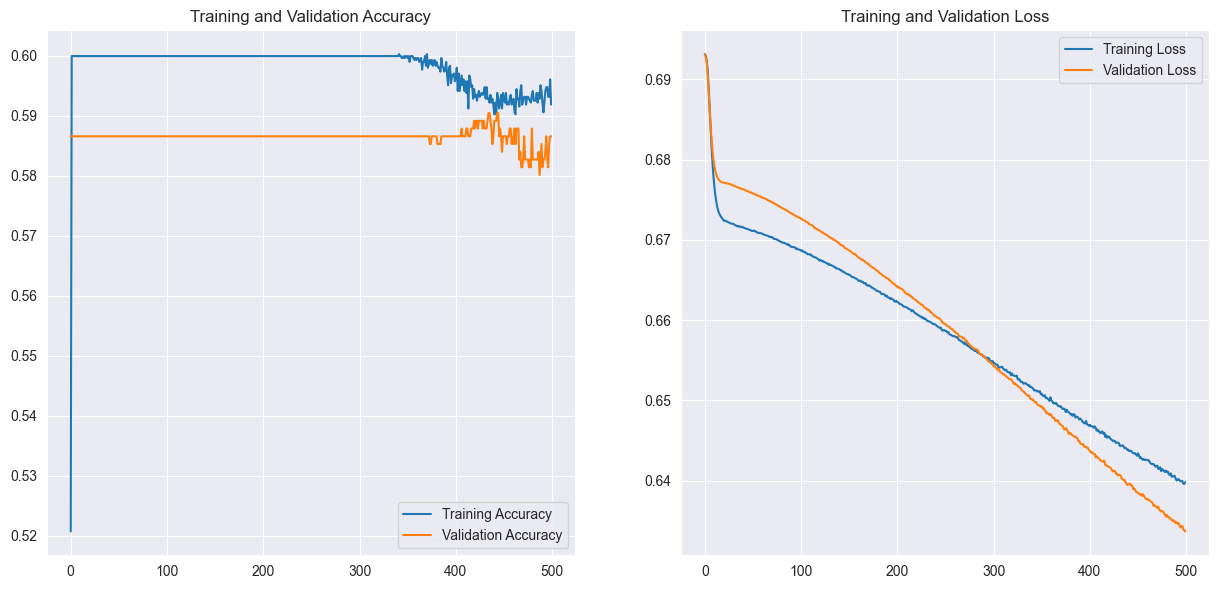

In [14]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(500)

plt.figure(figsize=(15, 15))
plt.subplot(2, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [15]:
#predictions = (model.predict(x_val) > 0.5).astype("int32")
predict_x = model.predict(x_val)
classes_x=np.argmax(predict_x,axis=1)
print(classification_report(y_val, classes_x, target_names = ['Building (Class 0)','Other (Class 1)']))

25/25 [==============================] - 3s 108ms/step
                    precision    recall  f1-score   support

Building (Class 0)       0.50      0.07      0.12       320
   Other (Class 1)       0.59      0.95      0.73       454

          accuracy                           0.59       774
         macro avg       0.55      0.51      0.42       774
      weighted avg       0.55      0.59      0.48       774



In [16]:
from tensorflow.keras.models import save_model
save_model(model, 'modeldata/building-detector-v12-gray.h5')

from tensorflow.keras.models import load_model
model_loaded = load_model('C:/DEV/imageprocess/modeldata/building-detector-v1.h5')

predict_x = model_loaded.predict(x_val)
classes_x=np.argmax(predict_x,axis=1)
print(classification_report(y_val, classes_x, target_names = ['Building (Class 0)','Other (Class 1)']))

In [1]:

import os
cwd = os.getcwd()
os.environ["PATH"] += os.pathsep + "C:/LAB/supporting/DOT"
#os.environ["PATH"] += os.pathsep + cwd + "\\DOT"

import keras

from tensorflow.keras.models import load_model
model_loaded = load_model('C:/DEV/imageprocess/modeldata/building-detector-v7.h5')

keras.utils.plot_model(model_loaded, "architecture.png", show_shapes=True)


OSError: No file or directory found at C:/DEV/imageprocess/modeldata/building-detector-v7.h5